## 1. Install dependencies

In [1]:
import sys
!pip -q install torch-geometric
try:
    import torch_geometric, torch
    print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
          '| PyG', torch_geometric.__version__)
except Exception as e:
    print('install issue:', e)

torch 2.10.0+cu128 | CUDA True | PyG 2.8.0.post1


 2. Load the project code into the writable working directory

In [2]:
import shutil, os, sys

# Show every input so it's easy to see what's mounted
print('Available under /kaggle/input:')
for base, dirs, files in os.walk('/kaggle/input'):
    if base.count('/') <= 4:
        print('  ', base, '->', dirs[:8])

# Find the project root at ANY depth (folder containing both src/ and experiments/)
root = None
for base, dirs, _ in os.walk('/kaggle/input'):
    if 'src' in dirs and 'experiments' in dirs:
        root = base; break
assert root, ('Code not found. Add your "forest-fire-gat" dataset via Add Input '
              '(see the tree printed above).')

WORK = '/kaggle/working/forest_fire_gat'
if os.path.exists(WORK): shutil.rmtree(WORK)
shutil.copytree(root, WORK)
os.chdir(WORK); sys.path.insert(0, WORK)
print('Project ready at', WORK, '->', sorted(os.listdir(WORK)))

Available under /kaggle/input:
   /kaggle/input -> ['datasets']
   /kaggle/input/datasets -> ['rithi123', 'fantineh']
   /kaggle/input/datasets/rithi123 -> ['forest-fire-risk']
   /kaggle/input/datasets/fantineh -> ['next-day-wildfire-spread']
Project ready at /kaggle/working/forest_fire_gat -> ['.gitignore', 'DATA.md', 'README.md', 'app.py', 'data', 'experiments', 'figures', 'models', 'notebooks', 'requirements.txt', 'results', 'src']


3. Link the NDWS dataset into `data/raw/`

In [3]:
import glob, os
os.makedirs('data/raw', exist_ok=True)

# Search EVERY attached input at any depth (mount path can vary)
files = glob.glob('/kaggle/input/**/*.tfrecord', recursive=True)

if not files:
    print('No *.tfrecord found. Here is everything under /kaggle/input:')
    for base, dirs, fs in os.walk('/kaggle/input'):
        for fn in fs[:15]:
            print('  ', os.path.join(base, fn))
    raise AssertionError('No tfrecords — check the listing above for real names/paths.')

files = sorted(set(files))
for f in files:
    dst = os.path.join('data/raw', os.path.basename(f))
    if not os.path.exists(dst):
        os.symlink(f, dst)

from src.data.ndws_reader import find_tfrecords
print(len(files), 'tfrecords linked |',
      'train', len(find_tfrecords('train')),
      'eval', len(find_tfrecords('eval')),
      'test', len(find_tfrecords('test')))

19 tfrecords linked | train 15 eval 2 test 2


## 4. Quick smoke test (synthetic — verifies the pipeline runs)

In [4]:
!python -m experiments.run_experiments --synthetic --epochs 6 --device cpu

Data source: SYNTHETIC (smoke test only — not for reported results) | device: cpu | seeds: [42, 1, 7]
  train: 40 tiles
  val  : 10 tiles
  test : 10 tiles
Train label counts: {'Low': 39472, 'Medium': 928, 'High': 560} | ignore 0

--------------------------------------------------  SEED 42
  [logreg] macroF1=0.3449
  [rf] macroF1=0.4672
  [mlp] macroF1=0.4997
  [gcn] macroF1=0.6791 acc=0.9019
  [gat] macroF1=0.8450 acc=0.9729
  [stgat] macroF1=0.8441 acc=0.9756

--------------------------------------------------  SEED 1
  [logreg] macroF1=0.3449
  [rf] macroF1=0.4600
  [mlp] macroF1=0.4900
  [gcn] macroF1=0.6803 acc=0.9119
  [gat] macroF1=0.7974 acc=0.9559
  [stgat] macroF1=0.7950 acc=0.9574

--------------------------------------------------  SEED 7
  [logreg] macroF1=0.3449
  [rf] macroF1=0.4672
  [mlp] macroF1=0.5133
  [gcn] macroF1=0.6799 acc=0.9016
  [gat] macroF1=0.8313 acc=0.9688
  [stgat] macroF1=0.7966 acc=0.9655
Paired comparisons (macro-F1): {'gat_vs_gcn': {'mean_diff': 0.14

 5. Run on real NDWS data (GPU)

In [5]:
# RECOMMENDED — 10 seeds for statistical significance (~2.5-3 h on GPU).
# Proposed model = ST-GAT (temporal); paired t-tests: ST-GAT vs GCN and ST-GAT vs GATv2.
!python -m experiments.run_experiments --device cuda --epochs 40 --max-train 2500 --max-eval 800 \
    --seeds 42,1,7,13,21,44,88,101,202,303

Data source: NDWS (real data) | device: cuda | seeds: [42, 1, 7, 13, 21, 44, 88, 101, 202, 303]
  train: 2232 tiles
  val  : 708 tiles
  test : 700 tiles
Train label counts: {'Low': 2120779, 'Medium': 96607, 'High': 50407} | ignore 17775

--------------------------------------------------  SEED 42
  [logreg] macroF1=0.4174
  [rf] macroF1=0.4776
  [mlp] macroF1=0.4715
  [gcn] macroF1=0.5679 acc=0.9134
  [gat] macroF1=0.5721 acc=0.8999
  [stgat] macroF1=0.5818 acc=0.8980

--------------------------------------------------  SEED 1
  [logreg] macroF1=0.4342
  [rf] macroF1=0.4788
  [mlp] macroF1=0.4706
  [gcn] macroF1=0.5390 acc=0.8970
  [gat] macroF1=0.5690 acc=0.9010
  [stgat] macroF1=0.5918 acc=0.9024

--------------------------------------------------  SEED 7
  [logreg] macroF1=0.4335
  [rf] macroF1=0.4788
  [mlp] macroF1=0.4675
  [gcn] macroF1=0.5451 acc=0.8972
  [gat] macroF1=0.5515 acc=0.8850
  [stgat] macroF1=0.5766 acc=0.8890

--------------------------------------------------  SEE

In [ ]:
# Optional quick check first (1 seed, small — a few minutes):
# !python -m experiments.run_experiments --device cuda --epochs 30 --seeds 42 --max-train 800 --max-eval 300

# Faster alternative if 3 hours is too long — 5 seeds (~1.5 h), still improves significance:
# !python -m experiments.run_experiments --device cuda --epochs 40 --max-train 2500 --max-eval 800 --seeds 42,1,7,13,21

## 6. Results, tables and figures

In [6]:
!python -m experiments.make_report
import pandas as pd
print(pd.read_csv('results/comparison_table.csv').to_string(index=False))
print()
print(pd.read_csv('results/ablation_table.csv').to_string(index=False))

wrote /kaggle/working/forest_fire_gat/results/paper_tables.md
# Experiment results (NDWS (real data)) — 10 seeds [42, 1, 7, 13, 21, 44, 88, 101, 202, 303]

## Table 1. Model comparison (mean ± std over seeds)

| Model | Accuracy | Macro-F1 | F1 (Low) | F1 (Medium) | F1 (High) |
| --- | --- | --- | --- | --- | --- |
| Logistic Regression | 0.702 ± 0.007 | 0.430 ± 0.010 | 0.827 | 0.107 | 0.357 |
| Random Forest | 0.929 ± 0.000 | 0.477 ± 0.002 | 0.966 | 0.060 | 0.405 |
| MLP | 0.926 ± 0.003 | 0.471 ± 0.003 | 0.964 | 0.049 | 0.401 |
| GCN | 0.902 ± 0.008 | 0.551 ± 0.011 | 0.958 | 0.270 | 0.426 |
| GATv2 (spatial) | 0.899 ± 0.005 | 0.566 ± 0.009 | 0.956 | 0.312 | 0.429 |
| ST-GAT (proposed) | 0.897 ± 0.004 | 0.579 ± 0.009 | 0.954 | 0.341 | 0.442 |


## Table 2. Ablation study (macro-F1, mean ± std)

| Variant | Macro-F1 |
| --- | --- |
| MLP (no graph) | 0.471 ± 0.003 |
| GCN | 0.551 ± 0.011 |
| GATv2 (spatial) | 0.566 ± 0.009 |
| ST-GAT (proposed) | 0.579 ± 0.009 |


## Feature-level expla

model_comparison


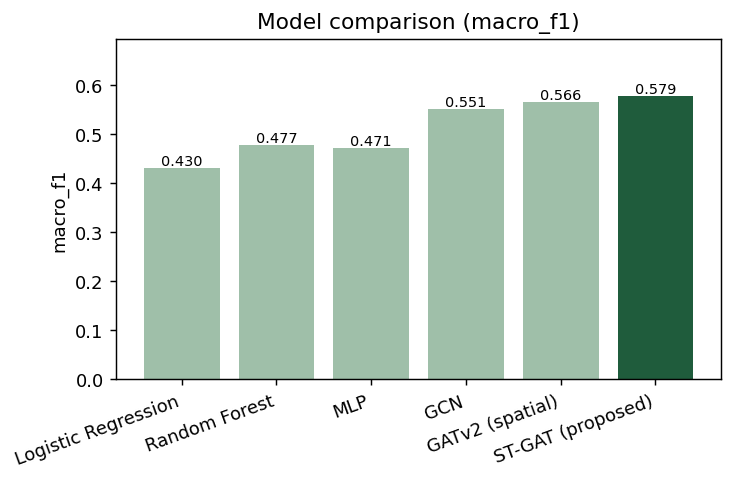

confusion_matrix


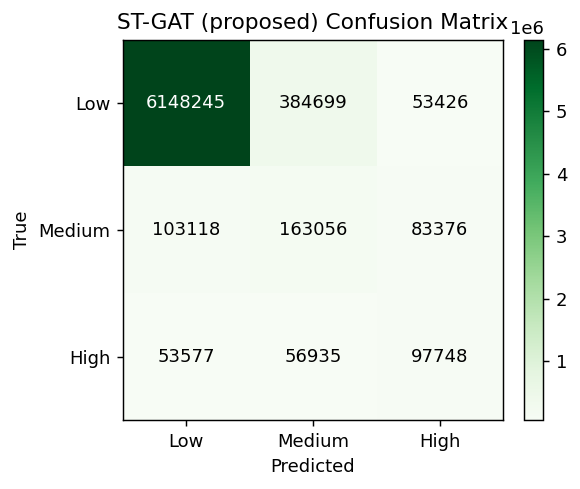

confusion_matrix_normalized


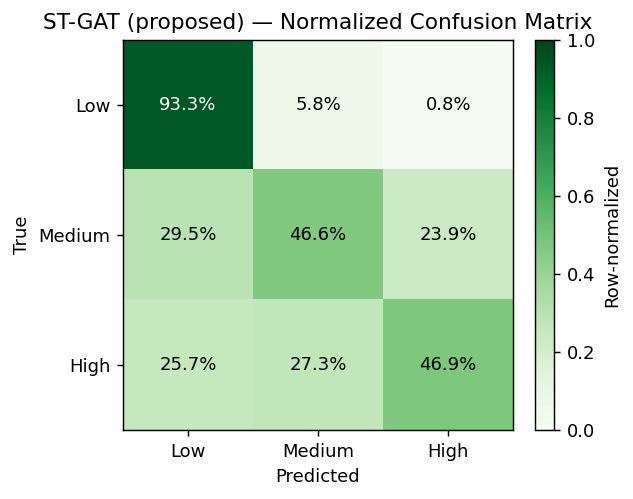

feature_importance


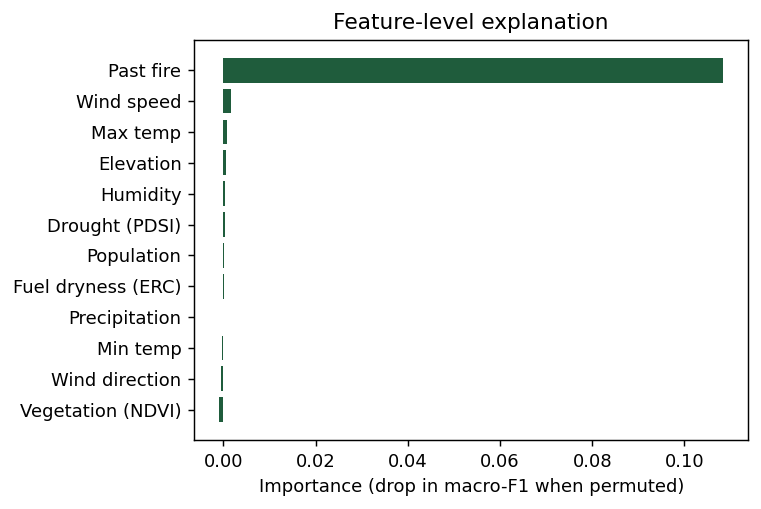

spatial_attention


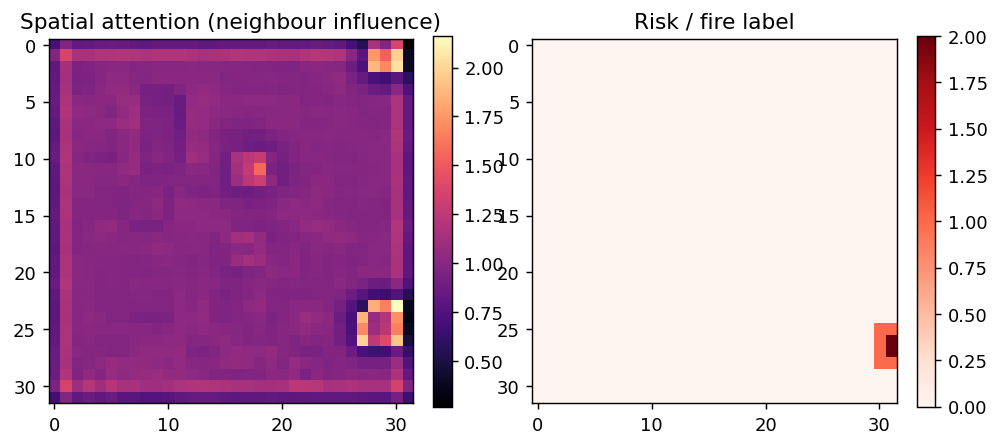

In [7]:
from IPython.display import Image, display
# Figures used in the paper (all generated for the proposed ST-GAT):
for f in ['model_comparison', 'confusion_matrix', 'confusion_matrix_normalized',
          'feature_importance', 'spatial_attention']:
    print(f); display(Image(f'figures/{f}.png'))

In [10]:
import shutil, glob, os
for src in ['results', 'figures', 'models']:
    dst = f'/kaggle/working/{src}'
    if os.path.isdir(src) and not os.path.exists(dst):
        shutil.copytree(src, dst)
print('Copied results/figures/models to /kaggle/working for easy download.')
print('Trained model:', glob.glob('models/*.pt'))

Copied results/figures/models to /kaggle/working for easy download.
Trained model: ['models/gcn.pt', 'models/stgat.pt', 'models/stgat_no_temporal.pt', 'models/gat.pt']
